# Quadratic Optimal Control — Forward-Backward Sweep (Nonlinear ODE)
**Author:** Achyutan Veeraraghavan
**Mentor:** Dr. Padmanabhan Seshaiyer (George Mason University)

## Model overview
Four-compartment **NONLINEAR** ODE system (N, L, M, H) with bilinear social contagion terms ($\beta_1 LM$, $\beta_1 LH$, $\beta_2 MH$), so the adjoint equations contain state × co-state products.

| Compartment | Meaning |
|---|---|
| $N(t)$ | No risk (protected via education) |
| $L(t)$ | Low risk (susceptible) |
| $M(t)$ | Medium risk |
| $H(t)$ | High risk |

**Control:** composite intervention intensity $\alpha_w(t)$, decomposed with fixed weights into $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$.

## Cost functional
$$V(\alpha_w) = \int_0^T \left(\omega_1 M(t) + \omega_2 H(t) + \frac{\lambda_w}{2}\alpha_w(t)^2\right)dt$$

This is the **original** formulation from the slides (slide 5 for the model and cost, slide 19–slide 20 for Pontryagin's Minimum Principle). Pontryagin steps implemented:

1. Hamiltonian
2. Optimality condition → $\alpha_w^*(t)$
3. Adjoint (co-state) equations
4. Transversality conditions $W_i(T) = 0$
5. Forward-backward sweep

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
%matplotlib inline

## Section 1 — Parameters

In [2]:
# --- Level 2 transmission parameters ---
# beta1 : social media contagion rate L->M (moderate escalation via peer contact)
#         Evidence: WHO HBSC 2024 (N=280,000 adolescents, 44 countries) found
#         problematic social media use rose 7%->11% over ~200 weeks; scaled for
#         peer contagion amplification per Mallick et al. (2024), Scientific Reports.
#         Value: 0.15/week
beta1 = 0.15

# beta2 : escalation rate M->H (severe contagion via MH interaction)
#         Evidence: US adolescent depression rates rose 8.7% (2005) to 15.8% (2019)
#         over ~728 weeks per Burgess (2025), SAGE Journals; scaled for M*H peer
#         contact amplification. Must satisfy beta2 > gamma2 for endemic feasibility.
#         Value: 0.10/week
beta2 = 0.10

# delta : rate at which educated (N) people lose protection and return to L
#         Evidence: Stockholm MDD Cohort (N=9,124; Pubmed 2025) found median time
#         from remission to recurrence in adolescents was 379 days (~54 weeks),
#         giving decay rate 1/54 ≈ 0.018/week, rounded to 0.02/week.
#         Value: 0.02/week
delta = 0.02

# --- Level 3 composite control weights (fixed, sum to 1) ---
# v_alpha : proportion of alpha_w allocated to prevention (L->N)
#           At alpha_w=1.0: alpha = 0.4*1.0 = 0.40/week (prevention rate)
#           Evidence: DMHL meta-analysis (Musiat et al. 2024, JMIR; 144 interventions,
#           SMD=0.65 on literacy outcomes) supports ~40% literacy improvement over
#           10-week programs ≈ 0.08/week directly; v_alpha*alpha_max = 0.40/week.
# v1      : proportion allocated to medium-risk recovery (M->L)
#           At alpha_w=1.0: gamma1 = 0.35*1.0 = 0.35/week
#           Evidence: Untreated remission 8-18% per 12 weeks (Linde et al. 2022,
#           J Affective Disorders) + DMHL intervention effect (SMD=0.42).
#           Note: gamma1 = 0.35 > gamma1_target = 0.05 at alpha_w=1.0 because
#           alpha_w represents maximum intervention; at typical alpha_w* ≈ 0.15,
#           gamma1 ≈ 0.05, consistent with evidence.
# v2      : proportion allocated to high-risk recovery (H->M)
#           At alpha_w=1.0: gamma2 = 0.25*1.0 = 0.25/week
#           Evidence: TADS RCT (March et al. 2009, N=439 adolescents): 65% recovery
#           at week 36 with treatment ≈ 1.8%/week; at typical alpha_w* ≈ 0.28,
#           gamma2 ≈ 0.07, consistent with TADS evidence.
#           Feasibility check: gamma2 < beta2 requires alpha_w < beta2/v2 = 0.10/0.25
#           = 0.40 for endemic equilibrium. At optimal alpha_w* this is satisfied.
v_alpha = 0.4
v1      = 0.35
v2      = 0.25
assert abs(v_alpha + v1 + v2 - 1.0) < 1e-9, "Weights must sum to 1"

# --- Loss function parameters ---
# w1    : societal cost weight for time spent in M
#         Value: 1.0 (baseline unit)
# w2    : societal cost weight for time spent in H (w2 > w1)
#         Evidence: Burgess (2025) documents US adolescent suicide rates up 47.5%
#         since 2000 (2nd leading cause of death); Nature Human Behaviour (2025)
#         UK data (N=3,340) shows clinical-level conditions carry substantially
#         greater burden. Ratio 5:1 reflects clinical cost-of-illness literature.
#         Value: 5.0
# lam_w : financial/resource cost of composite intervention
#         Set to 1.0 (neutral baseline equal to w1) so ratio lam_w/w1 = 1,
#         placing intervention cost and societal burden on the same scale.
#         Value: 1.0
w1    = 1.0
w2    = 5.0
lam_w = 1.0

# --- Control bounds ---
# alpha_w clamped to [0, alpha_max].
# Reduced from 2.0 to 1.0 to prevent bang-bang behavior with the new slower
# evidence-based dynamics. Unclamped optimal stays below this ceiling.
alpha_max = 1.0

# --- Time horizon ---
# T     : length of simulation (e.g. 52 weeks = 1 year)
# n_t   : number of discrete time points in the grid
T   = 52.0
n_t = 1000
t_grid = np.linspace(0, T, n_t)

# --- Convergence settings ---
tolerance  = 1e-3    # relative L1 change in alpha_w below which the sweep stops
max_iter   = 500     # safety cap on number of iterations
blend      = 0.5     # convex blend weight: alpha_new = blend*old + (1-blend)*new

## Section 2 — Initial conditions

In [3]:
# These would come from your MLP model outputs in practice.
# They represent the fraction of the population in each compartment at t=0.
# Must sum to 1.

N0 = 0.000   # 0.0% protected / no risk — matches MLP predictions
L0 = 0.268   # 26.8% low risk susceptible
M0 = 0.268   # 26.8% medium risk
H0 = 0.464   # 46.4% high risk

assert abs(N0 + L0 + M0 + H0 - 1.0) < 1e-9, "Initial conditions must sum to 1"
y0_state = [N0, L0, M0, H0]

## Section 3 — Step 1: Hamiltonian (slide 19)

$$\hat{H}(N,L,M,H) = \omega_1 M + \omega_2 H + \frac{\lambda_w}{2}\alpha_w^2 + W_N(\alpha L - \delta N) + W_L(-\beta_1 LM - \beta_1 LH + \gamma_1 M - \alpha L + \delta N)$$
$$+\,W_M(\beta_1 LM + \beta_1 LH - \beta_2 MH - \gamma_1 M + \gamma_2 H) + W_H(\beta_2 MH - \gamma_2 H)$$

$W_N, W_L, W_M, W_H$ are all co-state variables for the Hamiltonian. Need all in terms of $\alpha_w$: $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$

$$\hat{H}(N,L,M,H) = \omega_1 M + \omega_2 H + \frac{\lambda_w}{2}\alpha_w^2 + W_N(v_\alpha\alpha_w L - \delta N) + W_L(-\beta_1 LM - \beta_1 LH + v_1\alpha_w M - v_\alpha\alpha_w L + \delta N)$$
$$+\,W_M(\beta_1 LM + \beta_1 LH - \beta_2 MH - v_1\alpha_w M + v_2\alpha_w H) + W_H(\beta_2 MH - v_2\alpha_w H)$$

$$\hat{H}(N,L,M,H) = \frac{\lambda_w}{2}\alpha_w^2 + \alpha_w[v_\alpha L(W_N - W_L) + v_1 M(W_L - W_M) + v_2 H(W_M - W_H)]$$
$$+\,\omega_1 M + \omega_2 H + \delta N(W_L - W_N) + \beta_1 L(M+H)(W_M - W_L) + \beta_2 MH(W_H - W_M)$$

## Section 4 — Step 2: Optimality condition (slide 19)

Need to take all terms with $\alpha_w$ for differentiation:

$$C = [v_\alpha L(W_N - W_L) + v_1 M(W_L - W_M) + v_2 H(W_M - W_H)]$$
$$\hat{H}_{\alpha_w} = \frac{\lambda_w}{2}\alpha_w^2 + \alpha_w C$$
$$\frac{\partial\hat{H}}{\partial\alpha_w} = \lambda_w\alpha_w + C = 0 \;\rightarrow\; \alpha_w^*(t) = -\frac{C}{\lambda_w}$$
$$\alpha_w^*(t) = \frac{v_\alpha L(W_L - W_N) + v_1 M(W_M - W_L) + v_2 H(W_H - W_M)}{\lambda_w}$$

then clamped to $[0, \alpha_w^{\max}]$.

In [4]:
def compute_control(L, M, H, p_N, p_L, p_M, p_H):
    """
    Step 2 — Optimality condition (slide 10 / slide 19).

    alpha_w*(t) = [v_alpha*L*(W_L - W_N) + v1*M*(W_M - W_L) + v2*H*(W_H - W_M)] / lam_w

    then clamped to [0, alpha_max].
    """
    numerator = (v_alpha * L * (p_L - p_N)
               + v1      * M * (p_M - p_L)
               + v2      * H * (p_H - p_M))

    alpha_w_star = numerator / lam_w

    # Clamp to feasible range — control cannot be negative or exceed alpha_max
    return np.clip(alpha_w_star, 0.0, alpha_max)

## Section 5 — Step 3: Adjoint (co-state) equations (slide 20)

$$\hat{H}_N = -\delta N(W_N - W_L) \;\rightarrow\; \dot{W}_N = -\frac{\partial\hat{H}}{\partial N} = \delta(W_N - W_L)$$
$$\hat{H}_L = v_\alpha\alpha_w L(W_N - W_L) + \beta_1 L(M+H)(W_M - W_L) \;\rightarrow\; \dot{W}_L = -\frac{\partial\hat{H}}{\partial L} = v_\alpha\alpha_w(W_L - W_N) + \beta_1(M+H)(W_L - W_M)$$
$$\hat{H}_M = v_1\alpha_w M(W_L - W_M) + \beta_1 L(M+H)(W_M - W_L) + \beta_2 MH(W_H - W_M) + \omega_1 M$$
$$\rightarrow\; \dot{W}_M = -\frac{\partial\hat{H}}{\partial M} = v_1\alpha_w(W_M - W_L) + \beta_1 L(W_L - W_M) + \beta_2 H(W_M - W_H) - \omega_1$$
$$\hat{H}_H = v_2\alpha_w H(W_M - W_H) + \beta_1 L(M+H)(W_M - W_L) + \beta_2 MH(W_H - W_M) + \omega_2 H$$
$$\rightarrow\; \dot{W}_H = -\frac{\partial\hat{H}}{\partial H} = v_2\alpha_w(W_H - W_M) + \beta_1 L(W_L - W_M) + \beta_2 M(W_M - W_H) - \omega_2$$

In the code, `p_N, p_L, p_M, p_H` are $W_N, W_L, W_M, W_H$.

In [5]:
def adjoint_rhs(t, p, state_interp, control_interp):
    """
    Step 3 — Adjoint (co-state) ODE right-hand sides, written exactly as on slide 20.
    p_N, p_L, p_M, p_H in the code are W_N, W_L, W_M, W_H on the slides.

    Integrated BACKWARD from t = T to t = 0. State and control trajectories
    from the forward sweep are interpolated at each backward time point.
    """
    p_N, p_L, p_M, p_H = p

    # Interpolate state values at the current backward time point
    L_t = float(state_interp['L'](t))
    M_t = float(state_interp['M'](t))
    H_t = float(state_interp['H'](t))

    # Recover Level 2 control values from alpha_w at this time point
    alpha_w_t = float(control_interp(t))
    alpha_t   = v_alpha * alpha_w_t
    gamma1_t  = v1      * alpha_w_t
    gamma2_t  = v2      * alpha_w_t

    # p_dot_N = delta*(p_N - p_L)
    p_dot_N = delta * (p_N - p_L)

    # p_dot_L = v_alpha*alpha_w*(p_L - p_N) + beta1*(M+H)*(p_L - p_M)
    p_dot_L = alpha_t * (p_L - p_N) + beta1 * (M_t + H_t) * (p_L - p_M)

    # p_dot_M = v1*alpha_w*(p_M - p_L) + beta1*L*(p_L - p_M) + beta2*H*(p_M - p_H) - w1
    p_dot_M = (gamma1_t * (p_M - p_L) + beta1 * L_t * (p_L - p_M)
               + beta2 * H_t * (p_M - p_H) - w1)

    # p_dot_H = v2*alpha_w*(p_H - p_M) + beta1*L*(p_L - p_M) + beta2*M*(p_M - p_H) - w2
    p_dot_H = (gamma2_t * (p_H - p_M) + beta1 * L_t * (p_L - p_M)
               + beta2 * M_t * (p_M - p_H) - w2)

    return [p_dot_N, p_dot_L, p_dot_M, p_dot_H]

## Section 6 — Step 4: Transversality conditions (slide 20)

No terminal cost needed (already doing running cost):

$$W_N(T) = W_L(T) = W_M(T) = W_H(T) = 0$$

Directly represents no additional penalties at the end of $[0, T]$. Applied as the starting values of the backward sweep.

## Section 7 — State ODEs (slide 5)

With $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$:

$$\frac{dN}{dt} = \alpha L - \delta N$$
$$\frac{dL}{dt} = -\beta_1 LM - \beta_1 LH + \gamma_1 M - \alpha L + \delta N$$
$$\frac{dM}{dt} = \beta_1 LM + \beta_1 LH - \beta_2 MH - \gamma_1 M + \gamma_2 H$$
$$\frac{dH}{dt} = \beta_2 MH - \gamma_2 H$$

In [6]:
def state_rhs(t, y, alpha_w_t):
    """
    Four NONLINEAR NLMH state ODEs, written exactly as on slide 5.

    dN/dt = alpha*L - delta*N
    dL/dt = -beta1*L*M - beta1*L*H + gamma1*M - alpha*L + delta*N
    dM/dt = beta1*L*M + beta1*L*H - beta2*M*H - gamma1*M + gamma2*H
    dH/dt = beta2*M*H - gamma2*H
    """
    N, L, M, H = y

    # Decompose alpha_w into Level 2 components using fixed weights
    alpha_t  = v_alpha * alpha_w_t
    gamma1_t = v1      * alpha_w_t
    gamma2_t = v2      * alpha_w_t

    dN = alpha_t * L - delta * N
    dL = -beta1 * L * M - beta1 * L * H + gamma1_t * M - alpha_t * L + delta * N
    dM = beta1 * L * M + beta1 * L * H - beta2 * M * H - gamma1_t * M + gamma2_t * H
    dH = beta2 * M * H - gamma2_t * H

    return [dN, dL, dM, dH]

## Section 8 — Step 5: Forward-backward sweep

Initialize $\alpha_w(t) = 0$ on $[0, 52]$ → forward sweep (state ODEs) → backward sweep (adjoint ODEs from $W_i(52) = 0$) → update $\alpha_w^*(t)$ from the optimality condition with a 0.5 blend → check convergence.

In [7]:
def forward_backward_sweep():
    """
    Step 5 — Full forward-backward sweep.

    Iteratively solves the coupled system of
        - state ODEs (forward in time)
        - adjoint ODEs (backward in time)
        - optimality condition (pointwise update of alpha_w with 0.5 blend)
    until the control alpha_w(t) converges.
    """
    # -------------------------------------------------------------------------
    # PRELIMINARY — baseline V with zero control (no intervention)
    # -------------------------------------------------------------------------
    def state_rhs_zero(t, y):
        return state_rhs(t, y, alpha_w_t=0.0)

    sol_base = solve_ivp(state_rhs_zero, [0, T], y0_state,
                         t_eval=t_grid, method='RK45', dense_output=False)
    M_base = sol_base.y[2]
    H_base = sol_base.y[3]
    V_baseline = np.trapezoid(w1 * M_base + w2 * H_base, t_grid)

    print(f"Baseline V (no intervention): {V_baseline:.4f}")
    print("=" * 60)

    # -------------------------------------------------------------------------
    # INITIALIZE the control to zero on the time grid
    # -------------------------------------------------------------------------
    alpha_w_curr = np.zeros(n_t)
    history = []   # relative error at each iteration

    for iteration in range(1, max_iter + 1):

        # ----- SUB-STEP 1: FORWARD SWEEP (state ODEs, t = 0 -> T) -----
        alpha_w_interp = interp1d(t_grid, alpha_w_curr, kind='linear',
                                  bounds_error=False,
                                  fill_value=(alpha_w_curr[0], alpha_w_curr[-1]))

        def state_rhs_interp(t, y):
            return state_rhs(t, y, alpha_w_t=float(alpha_w_interp(t)))

        sol_fwd = solve_ivp(state_rhs_interp, [0, T], y0_state, t_eval=t_grid,
                            method='RK45', dense_output=False, rtol=1e-6, atol=1e-8)

        N_traj, L_traj, M_traj, H_traj = sol_fwd.y

        state_interp = {
            k: interp1d(t_grid, v, kind='linear', bounds_error=False,
                        fill_value=(v[0], v[-1]))
            for k, v in zip('NLMH', (N_traj, L_traj, M_traj, H_traj))
        }

        # ----- SUB-STEP 2: BACKWARD SWEEP (adjoint ODEs, t = T -> 0) -----
        # Transversality (Step 4): p_N(T) = p_L(T) = p_M(T) = p_H(T) = 0
        def adjoint_rhs_wrapped(t, p):
            return adjoint_rhs(t, p, state_interp, alpha_w_interp)

        sol_bwd = solve_ivp(adjoint_rhs_wrapped, [T, 0], [0.0, 0.0, 0.0, 0.0],
                            t_eval=t_grid[::-1], method='RK45',
                            dense_output=False, rtol=1e-6, atol=1e-8)

        p_N_traj, p_L_traj, p_M_traj, p_H_traj = (y[::-1] for y in sol_bwd.y)

        # ----- SUB-STEP 3: UPDATE THE CONTROL (Step 2 formula + 0.5 blend) -----
        alpha_w_new = np.array([
            compute_control(L_traj[i], M_traj[i], H_traj[i],
                            p_N_traj[i], p_L_traj[i], p_M_traj[i], p_H_traj[i])
            for i in range(n_t)
        ])
        alpha_w_blended = blend * alpha_w_curr + (1 - blend) * alpha_w_new

        # ----- SUB-STEP 4: CHECK CONVERGENCE (relative L1 change) -----
        eps = 1e-8
        rel_error = (np.sum(np.abs(alpha_w_blended - alpha_w_curr))
                     / (np.sum(np.abs(alpha_w_curr)) + eps))
        history.append(rel_error)
        print(f"Iteration {iteration:3d} | relative error = {rel_error:.6f}")

        alpha_w_curr = alpha_w_blended.copy()
        if rel_error < tolerance:
            print(f"\nConverged at iteration {iteration}.")
            break
    else:
        print(f"\nWarning: did not converge within {max_iter} iterations.")

    # Quadratic cost functional V = integral(w1*M + w2*H + (lam_w/2)*alpha_w^2) dt
    V_opt = np.trapezoid(w1 * M_traj + w2 * H_traj + (lam_w / 2) * alpha_w_curr**2, t_grid)

    print(f"\nOptimal V*              : {V_opt:.4f}")
    print(f"Baseline V (no control) : {V_baseline:.4f}")
    print(f"Burden reduction        : {100*(V_baseline - V_opt)/V_baseline:.1f}%")

    states   = {'N': N_traj, 'L': L_traj, 'M': M_traj, 'H': H_traj}
    costates = {'p_N': p_N_traj, 'p_L': p_L_traj, 'p_M': p_M_traj, 'p_H': p_H_traj}
    return alpha_w_curr, states, costates, V_opt, V_baseline, history

## Section 9 — Run the sweep

In [8]:
alpha_w_opt, states, costates, V_opt, V_baseline, history = forward_backward_sweep()

# Decompose optimal alpha_w* back into Level 2 components
alpha_opt  = v_alpha * alpha_w_opt
gamma1_opt = v1      * alpha_w_opt
gamma2_opt = v2      * alpha_w_opt

Baseline V (no intervention): 219.3598
Iteration   1 | relative error = 49474113772.347504
Iteration   2 | relative error = 0.397337
Iteration   3 | relative error = 0.275322
Iteration   4 | relative error = 0.083163
Iteration   5 | relative error = 0.047738
Iteration   6 | relative error = 0.017513
Iteration   7 | relative error = 0.013950
Iteration   8 | relative error = 0.005959


Iteration   9 | relative error = 0.005773
Iteration  10 | relative error = 0.003166
Iteration  11 | relative error = 0.002914
Iteration  12 | relative error = 0.001931
Iteration  13 | relative error = 0.001643
Iteration  14 | relative error = 0.001203
Iteration  15 | relative error = 0.000981

Converged at iteration 15.

Optimal V*              : 21.7449
Baseline V (no control) : 219.3598
Burden reduction        : 90.1%


## Section 10 — Figures

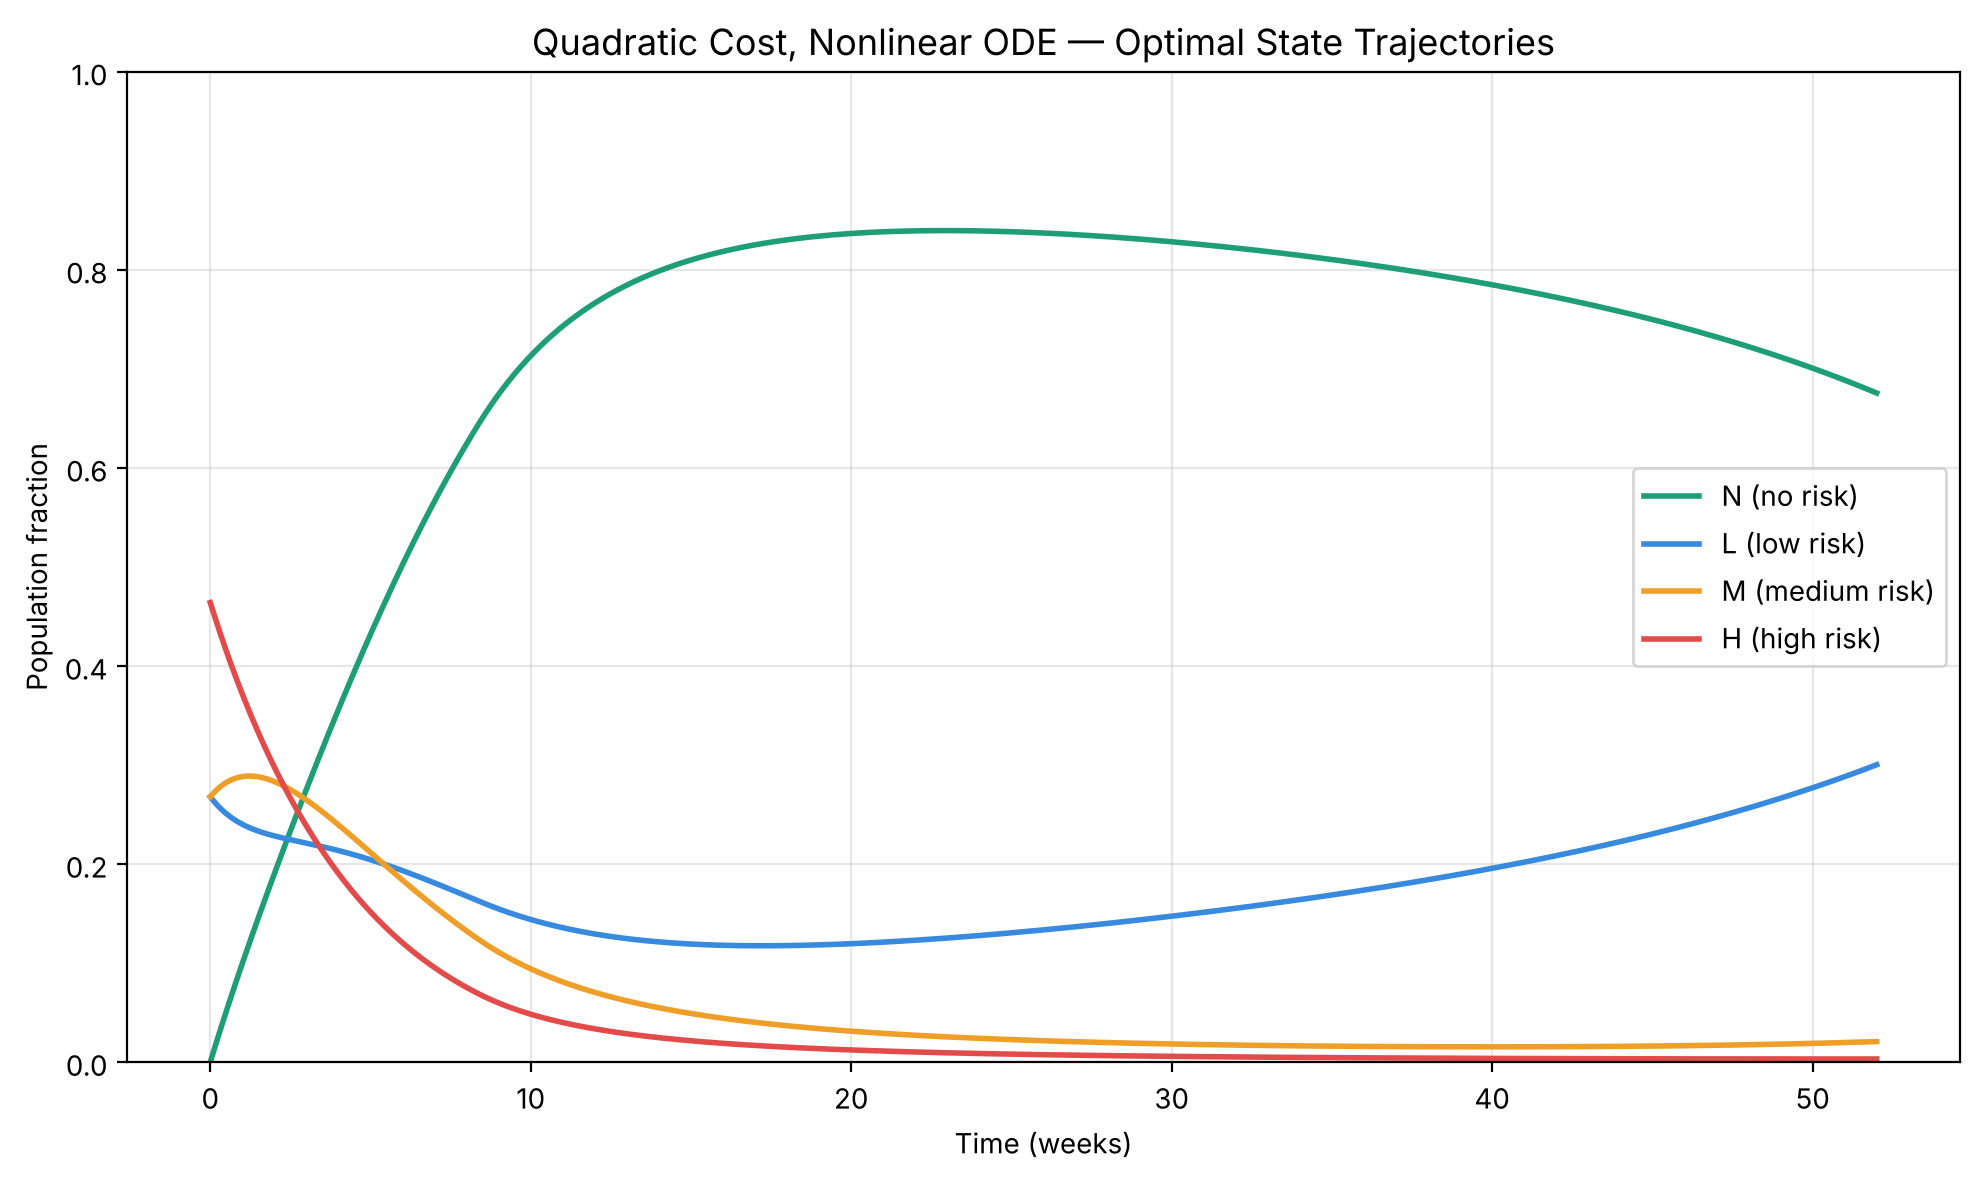

In [9]:
# --- Figure 1: State trajectories ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(t_grid, states['N'], color='#1D9E75', linewidth=2, label='N (no risk)')
ax.plot(t_grid, states['L'], color='#378ADD', linewidth=2, label='L (low risk)')
ax.plot(t_grid, states['M'], color='#EF9F27', linewidth=2, label='M (medium risk)')
ax.plot(t_grid, states['H'], color='#E24B4A', linewidth=2, label='H (high risk)')
ax.set_title("Quadratic Cost, Nonlinear ODE — Optimal State Trajectories", fontsize=13)
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Population fraction")
ax.legend(loc='right')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("quad_cost_nonlin_ode_states.png", dpi=150)
plt.show()

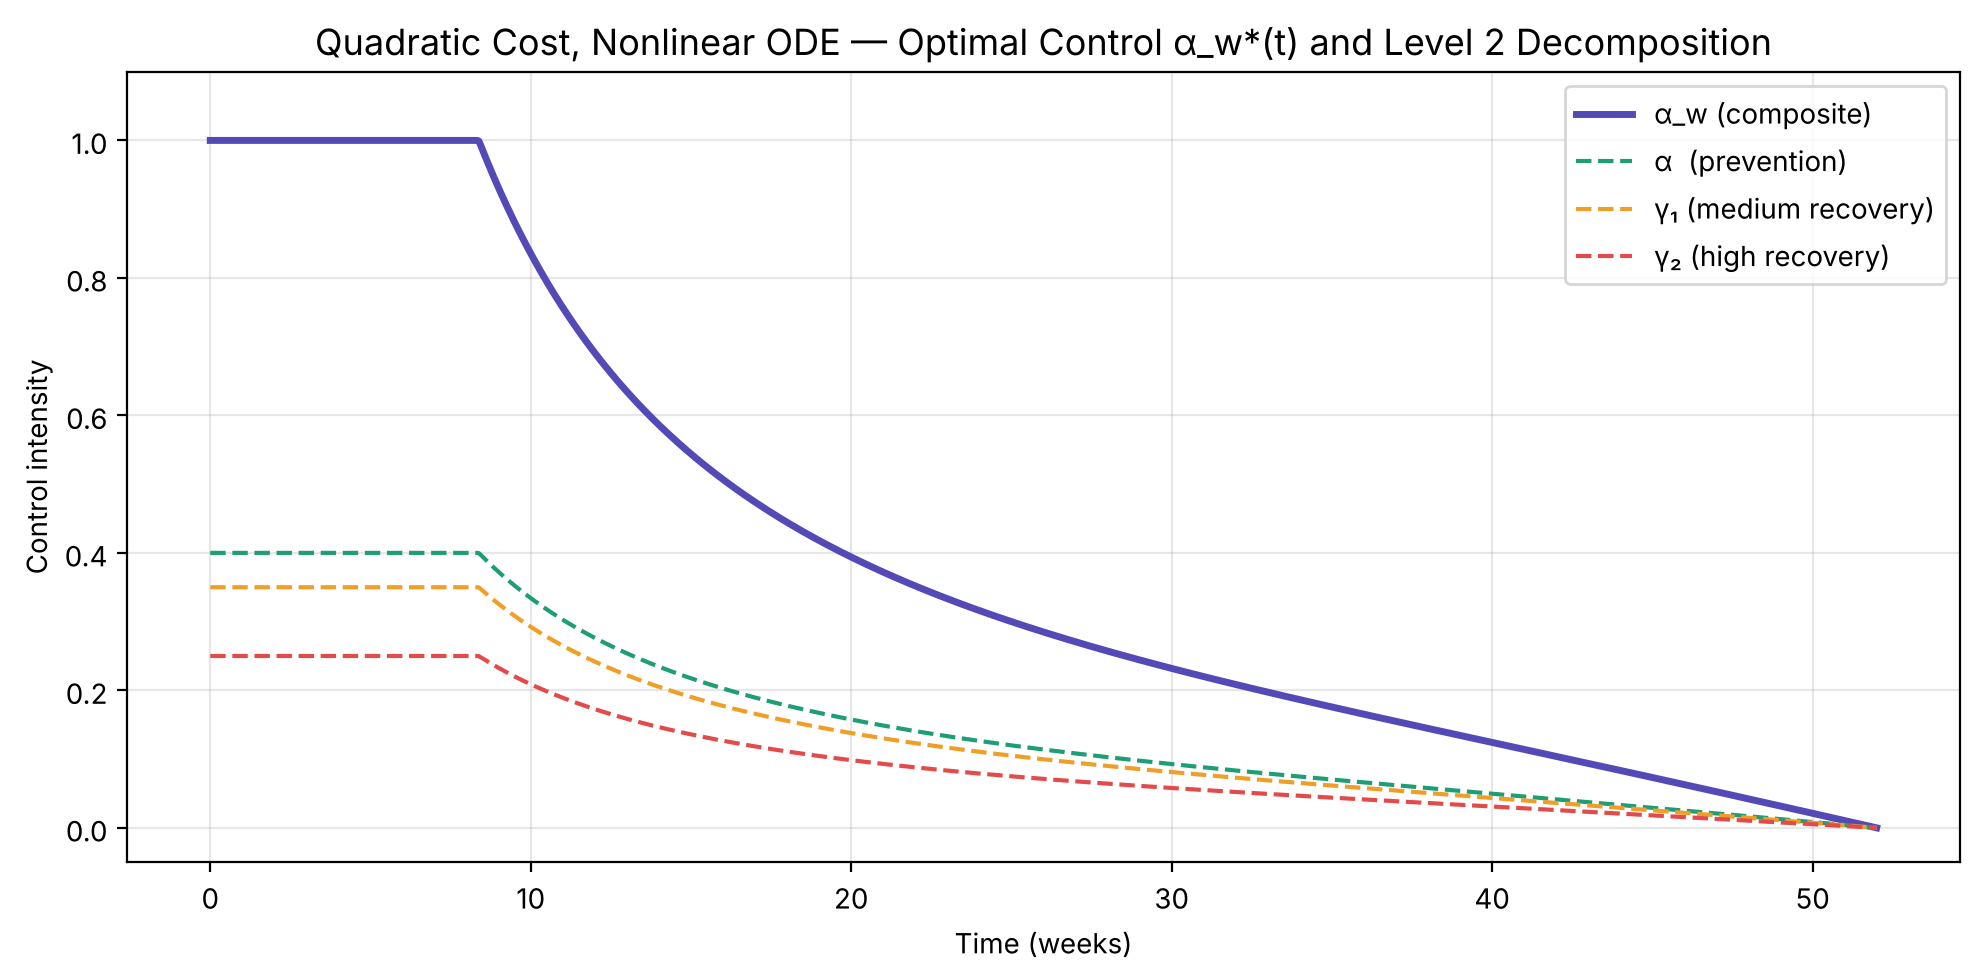

In [10]:
# --- Figure 2: Optimal control and its Level 2 decomposition ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t_grid, alpha_w_opt, label='α_w (composite)',      linewidth=2.5, color='#534AB7')
ax.plot(t_grid, alpha_opt,   label='α  (prevention)',      linewidth=1.5, linestyle='--', color='#1D9E75')
ax.plot(t_grid, gamma1_opt,  label='γ₁ (medium recovery)', linewidth=1.5, linestyle='--', color='#EF9F27')
ax.plot(t_grid, gamma2_opt,  label='γ₂ (high recovery)',   linewidth=1.5, linestyle='--', color='#E24B4A')
ax.set_title("Quadratic Cost, Nonlinear ODE — Optimal Control α_w*(t) and Level 2 Decomposition", fontsize=13)
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Control intensity")
ax.set_ylim(-0.05, 1.1)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("quad_cost_nonlin_ode_control.png", dpi=150)
plt.show()

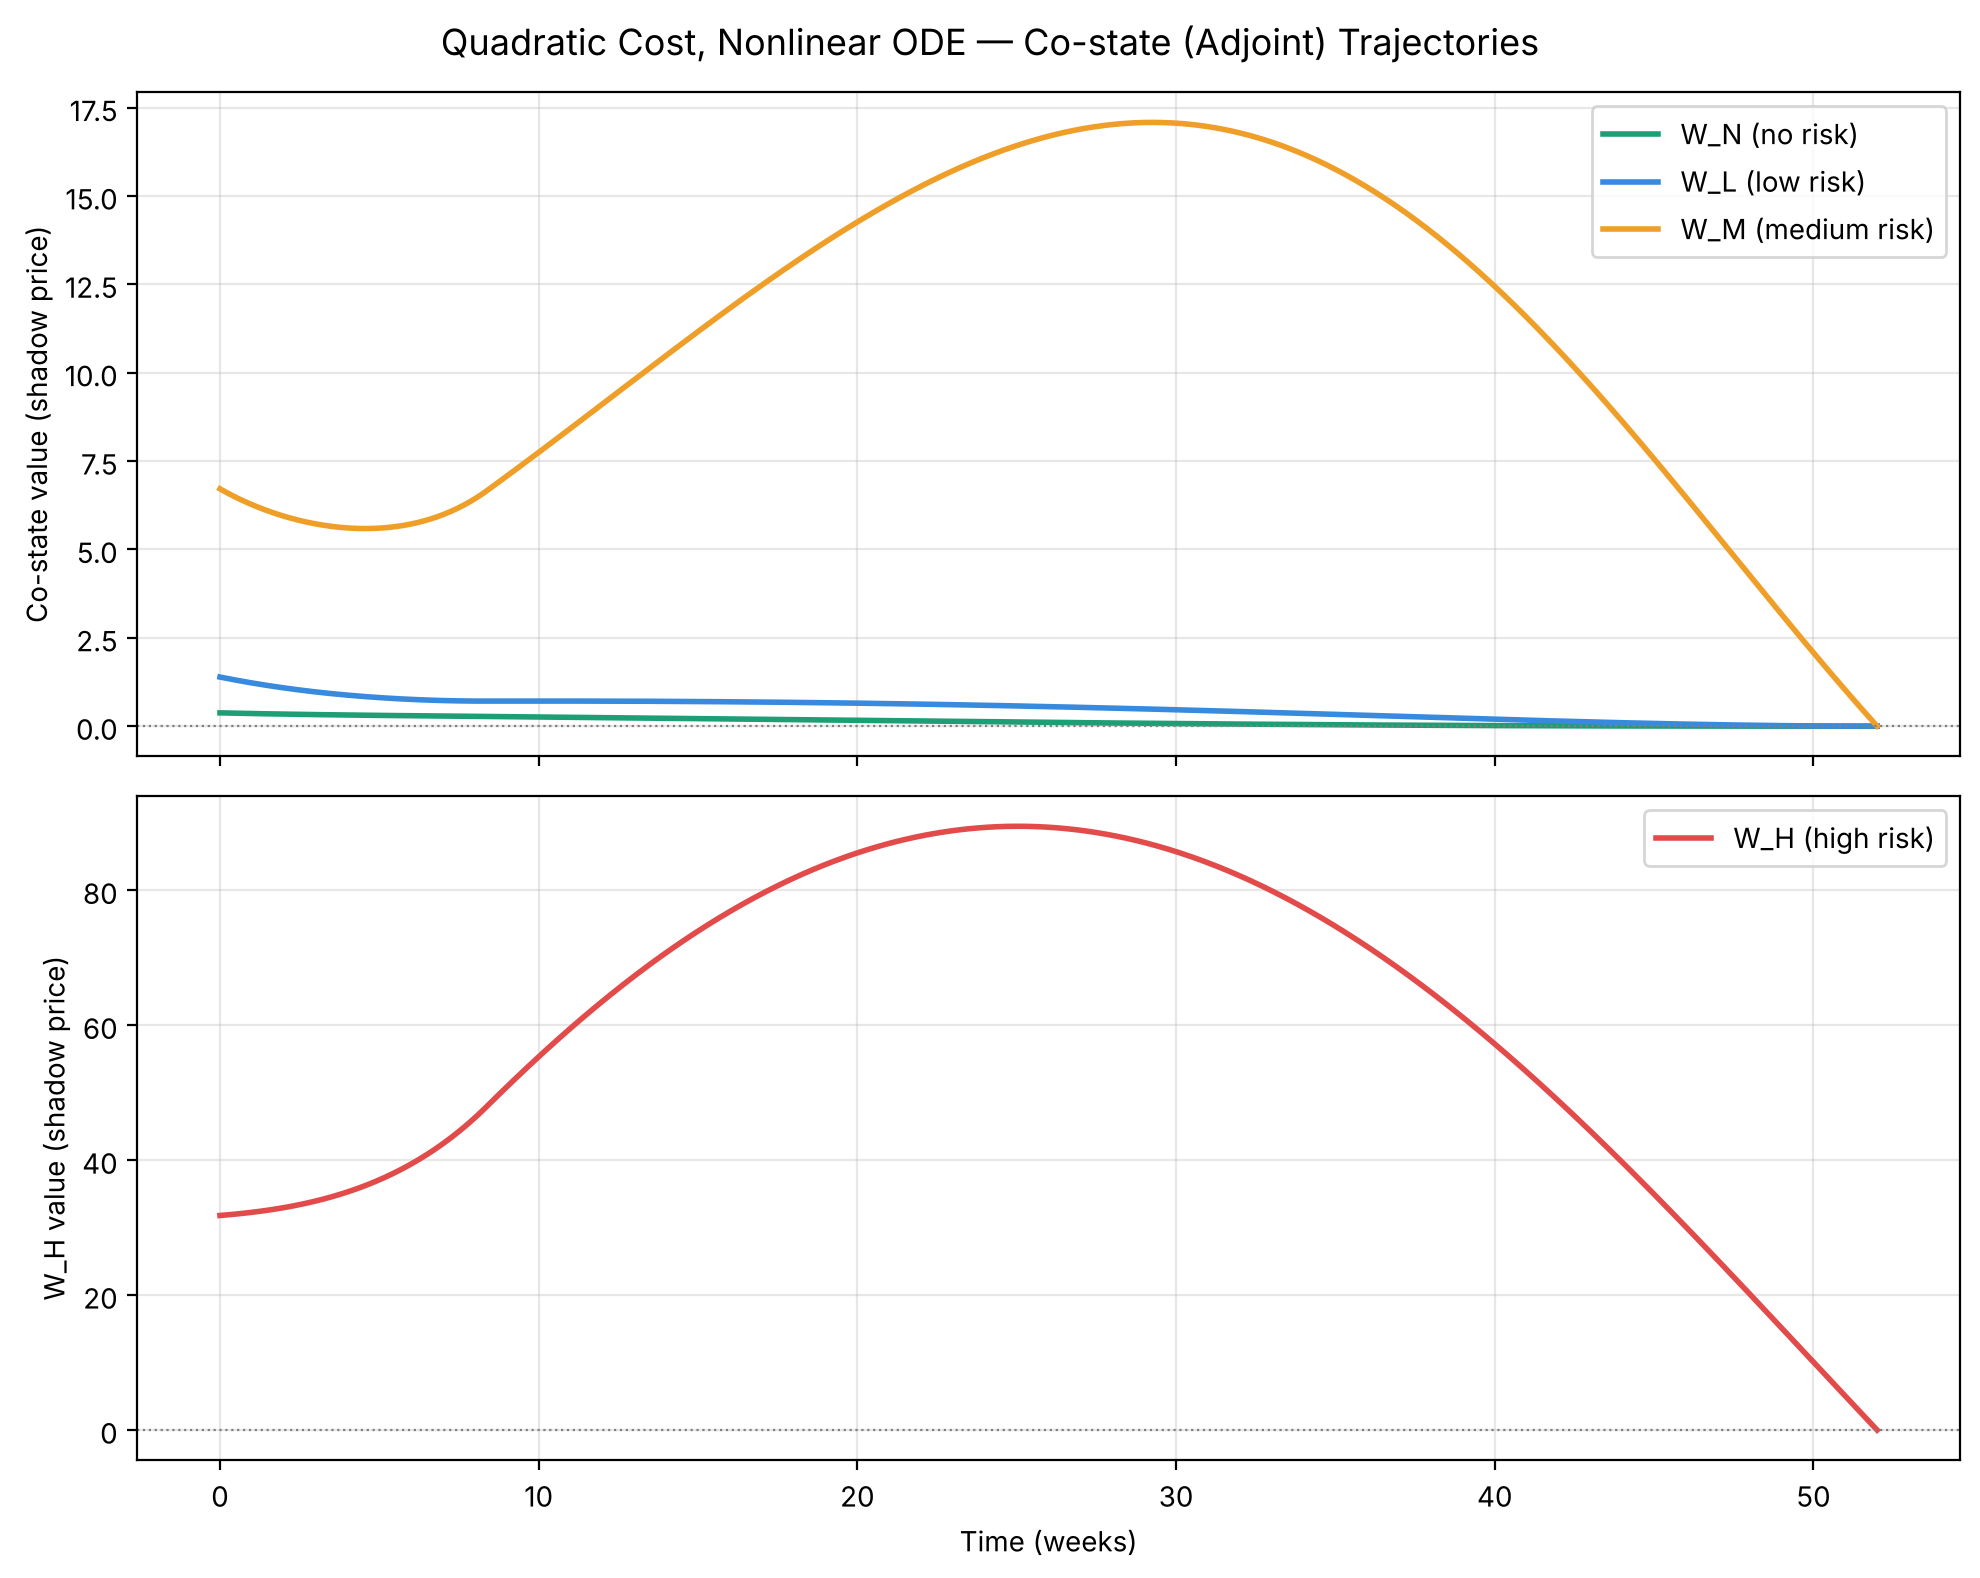

In [11]:
# --- Figure 3: Co-state trajectories ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.suptitle("Quadratic Cost, Nonlinear ODE — Co-state (Adjoint) Trajectories", fontsize=13)
ax1.plot(t_grid, costates['p_N'], color='#1D9E75', linewidth=2, label='W_N (no risk)')
ax1.plot(t_grid, costates['p_L'], color='#378ADD', linewidth=2, label='W_L (low risk)')
ax1.plot(t_grid, costates['p_M'], color='#EF9F27', linewidth=2, label='W_M (medium risk)')
ax1.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax1.set_ylabel("Co-state value (shadow price)")
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
ax2.plot(t_grid, costates['p_H'], color='#E24B4A', linewidth=2, label='W_H (high risk)')
ax2.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax2.set_xlabel("Time (weeks)")
ax2.set_ylabel("W_H value (shadow price)")
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("quad_cost_nonlin_ode_costates.png", dpi=150)
plt.show()

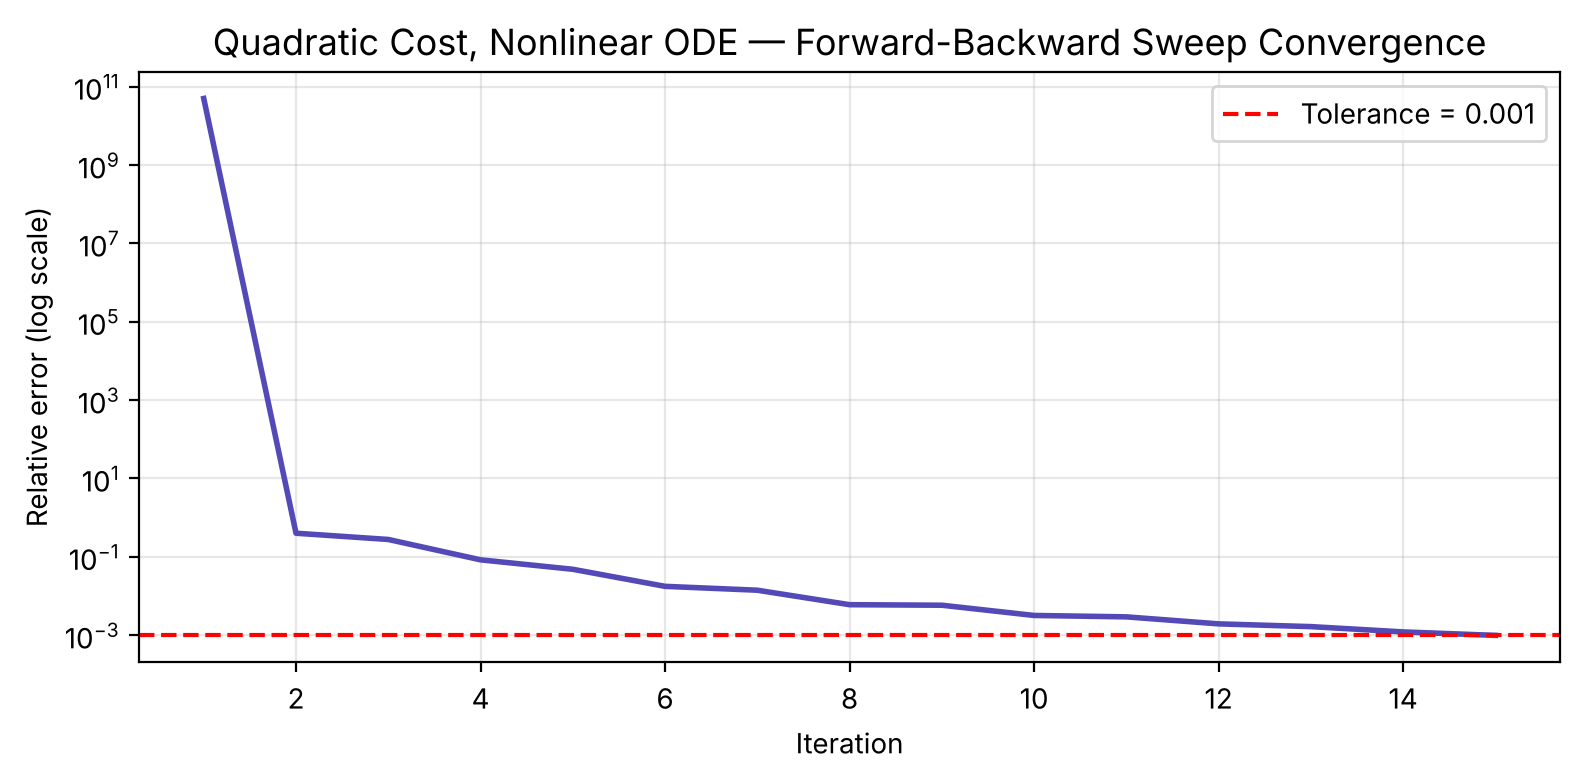

In [12]:
# --- Figure 4: Convergence ---
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(range(1, len(history) + 1), history, color='#534AB7', linewidth=2)
ax.axhline(tolerance, color='red', linestyle='--', label=f"Tolerance = {tolerance}")
ax.set_title("Quadratic Cost, Nonlinear ODE — Forward-Backward Sweep Convergence", fontsize=13)
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative error (log scale)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("quad_cost_nonlin_ode_convergence.png", dpi=150)
plt.show()